In [640]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from iq5model import iq5model 

class SpeedControllerPI:
    """모터 속도 제어를 위한 PI 제어기"""
    def __init__(self, kp, ki, output_limits=(-340, 340)):
        self.kp = kp
        self.ki = ki
        self.integral = 0.0
        self.min_out, self.max_out = output_limits

    def compute(self, target_speed, current_speed, dt):
        error = (target_speed - current_speed) # rad/s
        self.integral += error * dt
        self.integral = np.clip(self.integral, self.min_out / (self.ki + 1e-6), self.max_out / (self.ki + 1e-6))

        output = (self.kp * error) + (self.ki * self.integral)
        return np.clip(output, self.min_out, self.max_out)
iq5 = iq5model(Rs=0.0618,lut="./LUT_lamda_abcT_20261119_091223.csv")

[정보] 3상(ABC) 쇄교자속 LUT CSV 파일 로딩 및 보간기 생성 중...
[완료] ABC 보간기 생성 완료 (소요 시간: 3.17초)


In [641]:
dt = 0.0001

total_time = 0.2
target_speed_rpm = 500 # 목표 BEMF 측정 속도 [RPM]

total_steps = int(total_time / dt)

# 히스토리 기록용 리스트
time_history =  []
speed_history = []
v_a_history =   []
v_a0_history =  []
v_d_history =   []
v_d1_history =  []
temp1_history = []
temp2_history = []
idq0_history =  []
Torque_histroy =  []
Torque_histroy2 = []
Torque_histroy3 = []

xJ = np.array([
    [0, -1,  0],
    [1,  0,  0],
    [0,  0,  0]
])
load_torque = 0.0
bemf = np.zeros(3)
temp1 = np.zeros(3)
temp2 = np.zeros(3)
i_dq0 = np.zeros(3)

V_abc = np.zeros(3)
V_dq0 = np.zeros(3)
V_dq1 = np.zeros(3)
dlamda_dq0_dt2 = np.zeros(3)
dlamda_dq0_dt = np.zeros(3)
lamda_abc = np.zeros(3)
lamda_dq0_old = np.zeros(3)
lamda_abc_old = np.zeros(3)
current_radpsec = 0.0
theta_mech_cum = 0.0
did_dt = np.zeros(3)
i_dq0_old = np.zeros(3)
We_cross_lamda_dq0 = np.zeros(3)
i_dq0 = np.zeros(3)

# 속도 제어기 게인 조정 (오버슈트 및 윈드업 최소화를 위해 kp, ki 조정 및 리미트 최적화)
speed = SpeedControllerPI(kp=0.1, ki=1, output_limits=(-350, 350))
current_speed_rpm = 0.0
V_dq00 = np.zeros(3)
V_dq11 = np.zeros(3)

$$
\begin{aligned}
v_d &= R_s i_d + L_d \frac{di_d}{dt} - \omega_e L_q i_q \\
v_q &= R_s i_q + L_q \frac{di_q}{dt} + \omega_e (L_d i_d + \lambda_f) \\
L_d \frac{di_d}{dt} &= v_d - R_s i_d + \omega_e L_q i_q -  \omega_e \gamma_{d} \\
L_q \frac{di_q}{dt} &= v_q - R_s i_q - \omega_e L_d i_d - \omega_e \gamma_{q} - \omega_e  \lambda_f  
\end{aligned}
$$

In [642]:
def motor_equation2(V_dq0, i_dq0, We ,lamda_dq0,lamda_dq0_0, Ldq, gamma_dq0 ):
    did_dt=np.zeros(3)
    Rs = iq5.Rs
    vd,vq,id,iq = V_dq0[0],V_dq0[1],i_dq0[0],i_dq0[1]
    Ld,Lq = max(Ldq[0,0],1e-5),max(Ldq[1,1],1e-5)
    rd, rq, xf = gamma_dq0[0],gamma_dq0[1],lamda_dq0_0[0]
    did_dt[0] = (vd - Rs * id + We * Lq * iq - We * rd) / Ld
    did_dt[1] = (vq - Rs * iq - We * Ld * id - We * rq - We * xf ) / Lq
    did_dt[2] = 0
    np.clip(did_dt, [-350.0, -350.0, 0.0], [350.0, 350.0, 0.0])
    return did_dt

In [643]:
def motor_equation(V_dq0, i_dq0, We ,lamda_dq0,lamda_dq0_0, Ldq, gamma_dq0 ):
    did_dt = np.zeros(3)
    did_dt = np.linalg.inv(Ldq + np.eye(3)*1e-5) @ (V_dq0 - (iq5.Rs*i_dq0 + We*gamma_dq0 + np.linalg.cross([0,0,We],lamda_dq0))) 
    np.clip(did_dt, [-350.0, -350.0, 0.0], [350.0, 350.0, 0.0])
    return did_dt

$$
\begin{aligned}
v_{abc} &= R_s i_{abc} + \frac{d\lambda_{abc}}{dt} \\
v_{dq0} &= R_s i_{dq0} + \frac{d\lambda_{dq0}}{dt} + \mathbf{\omega_e} \times \lambda_{dq0} \\
v_{dq0} &= R_s i_{dq0} + L_{dq0} \frac{di_{dq0}}{dt} + \omega_e \gamma_{dq0}  + \mathbf{\omega_e} \times \lambda_{dq0}
\end{aligned}
$$

In [644]:
def voltage_equation(lamda_abc,lamda_abc_old, dt,lamda_dq0,lamda_dq0_old,We,Ldq,i_dq0,i_dq0_old,gamma_dq0):
    V_abc = (lamda_abc - lamda_abc_old) / dt
    dlamda_dq0_dt = (lamda_dq0 - lamda_dq0_old) / dt
    We_cross_lamda_dq0 = np.linalg.cross(np.array([0, 0, We]), lamda_dq0)
    V_dq0 = dlamda_dq0_dt + We_cross_lamda_dq0
    Ls_di_dq0_dt = Ldq @ (i_dq0 - i_dq0_old) / dt
    We_gamma_dq0 = We * gamma_dq0
    V_dq1 = Ls_di_dq0_dt + We_gamma_dq0 + We_cross_lamda_dq0
    return V_abc, V_dq0, V_dq1

$$
\begin{aligned}
T_m &= \frac{1}{2}P(\lambda_{dq0} \times i_{dq0})_0 + \frac{1}{2}P \gamma_{dq0}i_{dq0} \\
T_m &= \frac{1}{2}P(\lambda_d i_q + (L_d - L_q) i_d i_q) + \frac{1}{2}P \gamma_{dq0}i_{dq0} \\
T_{cog} &= \frac{1}{2}P \gamma_{dq0}i_{dq0} , P = PolePair
\end{aligned}
$$

In [645]:
def torgue_cal(gamma_dq0,i_dq0,Ldq ,lamda_dq0_0,lamda_dq0):
    T_cog = 1.5 * iq5.pole_pairs * gamma_dq0 @ i_dq0
    Te_z = 1.5 * iq5.pole_pairs * (lamda_dq0_0[0] * i_dq0[1] + (Ldq[0, 0] - Ldq[1, 1]) * i_dq0[0] * i_dq0[1]) + T_cog
    Te_z2 = (1.5 * iq5.pole_pairs * np.linalg.cross(lamda_dq0, i_dq0))[2] + T_cog
    return T_cog, Te_z, Te_z2

$$
\begin{aligned}
J\frac{d\omega_m}{dt} &= T_m - T_L - T_b
\end{aligned}
$$

In [646]:
# 모터 동역학 방정식 계산 (감쇄 효과)
def dynamics_equation(Tm, load_torque,current_radpsec):
  B_friction = 0.05  # 실제 기계 시스템 모사를 위한 약간의 마찰 계수 조정
  accel_rad_s2 = (Tm - load_torque - B_friction * current_radpsec) / iq5.Inertia
  current_radpsec += accel_rad_s2 * dt
  current_speed_rpm = current_radpsec * 30.0 / np.pi
  return current_radpsec, current_speed_rpm

In [647]:
for step in range(total_steps):
  current_time = step * dt

  # 전기각 계산 (0 ~ 360도 정규화)
  theta_elec_rad, theta_elec_deg = iq5.check_degree(theta_mech_cum * iq5.pole_pairs)
  lamda_abc, lamda_dq0_0, lamda_dq0, Ldq, gamma_dq0 = iq5.get_lambda(i_dq0[0], i_dq0[1], theta_elec_deg)

  We = current_radpsec * iq5.pole_pairs
  

  if step > 0:

      V_abc, V_dq00, V_dq11 = voltage_equation(lamda_abc,lamda_abc_old, dt,lamda_dq0,lamda_dq0_old,We,Ldq,i_dq0,i_dq0_old,gamma_dq0)
      # PI 제어 기반 전압 명령 생성 (안티윈드업 반영)
      v_ref = speed.compute(target_speed_rpm, current_speed_rpm, dt)

      V_dq0[0] = np.cos(np.radians(92.5)) * v_ref
      V_dq0[1] = np.sin(np.radians(92.5)) * v_ref
      V_dq0[2] = 0

     
      did_dt = motor_equation(V_dq0, i_dq0, We ,lamda_dq0,lamda_dq0_0, Ldq, gamma_dq0)
      
      i_dq0 += did_dt * dt

  idq0_history.append(i_dq0.copy())
      
  T_cog, Te_z, Te_z2 = torgue_cal(gamma_dq0,i_dq0,Ldq ,lamda_dq0_0,lamda_dq0)

  query_point_T = np.array([[i_dq0[0], i_dq0[1], theta_elec_deg]])
  torque = iq5.interp_T(query_point_T)[0]

  Torque_histroy.append(Te_z)
  Torque_histroy2.append(Te_z2)
  Torque_histroy3.append(torque)

  # 모터 동역학 방정식 계산 (감쇄 효과)
  current_radpsec, current_speed_rpm = dynamics_equation(Te_z, load_torque,current_radpsec)

  lamda_abc_old = lamda_abc.copy()
  lamda_dq0_old = lamda_dq0.copy()
  theta_elec_deg_old = theta_elec_deg
  i_dq0_old = i_dq0.copy()

  # 기계각 업데이트
  delta_mech_deg = (current_radpsec * dt) * (180 / np.pi)
  theta_mech_cum += delta_mech_deg
  theta_mech_cum %= 360.0

  # 기록
  time_history.append(current_time)
  speed_history.append(current_speed_rpm)
  v_a_history.append(iq5.dq_to_abc(V_dq00, theta_elec_rad))
  v_a0_history.append(iq5.dq_to_abc(V_dq0.copy(), theta_elec_rad))

  v_d_history.append(V_dq00)
  v_d1_history.append(V_dq0.copy())

 

 
  temp1_history.append(delta_mech_deg)
  temp2_history.append(dlamda_dq0_dt2)

print("[완료] BEMF 시뮬레이션 연산 완료. 그래프 생성 중...")



[완료] BEMF 시뮬레이션 연산 완료. 그래프 생성 중...


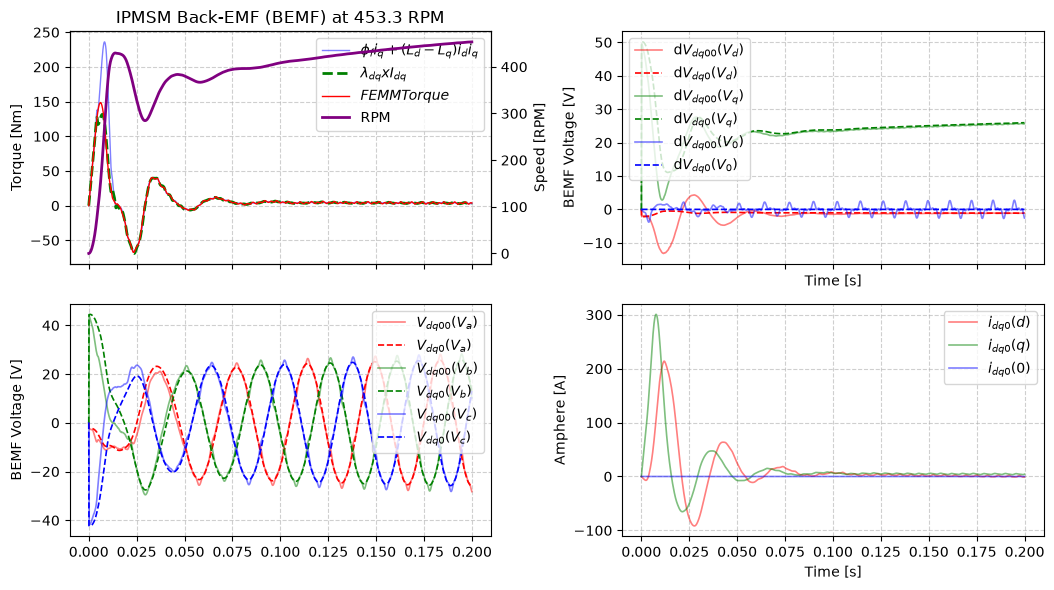

In [648]:
# --- 시각화 ---
fig, axes = plt.subplots(2, 2, figsize=(16*2/3, 9*2/3), sharex=True)
colors_rgb = ['red', 'green', 'blue']

ax = axes[0, 0]
ax_rpm = ax.twinx()

l1, = ax.plot(time_history, Torque_histroy, label=rf'$\phi_f i_q + (L_d - L_q) i_d i_q$', color='blue', linewidth=1, alpha=0.5)
l2, = ax.plot(time_history, Torque_histroy2, label=rf'$\lambda_{{dq}} x I_{{dq}}$', color='green', linewidth=2, linestyle='--')
l3, = ax.plot(time_history, Torque_histroy3, label='$FEMM Torque$', color='red', linewidth=1)
l4, = ax_rpm.plot(time_history, speed_history, label='RPM', color='purple', linewidth=2)

ax.set_ylabel('Torque [Nm]')
ax_rpm.set_ylabel('Speed [RPM]')
ax.grid(True, linestyle='--', alpha=0.6)
ax.set_title(rf'IPMSM Back-EMF (BEMF) at {current_speed_rpm:.1f} RPM')

lines = [l1, l2, l3, l4]
labels = [line.get_label() for line in lines]
ax.legend(lines, labels, loc='best')

labels = ["$V_a$", "$V_b$", "$V_c$"]
for i in range(3):
    axes[1, 0].plot(time_history, np.array(v_a_history)[:, i], label=rf'$V_{{dq00}}$({labels[i]})', color=colors_rgb[i], linewidth=1.2, alpha=0.5)
    axes[1, 0].plot(time_history, np.array(v_a0_history)[:, i], label=rf'$V_{{dq0}}$({labels[i]})', color=colors_rgb[i], linewidth=1.2, linestyle='--')
axes[1, 0].set_ylabel('BEMF Voltage [V]')
axes[1, 0].legend(loc='best')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

labels = ["$V_d$", "$V_q$", "$V_0$"]
for i in range(3):
    axes[0, 1].plot(time_history, np.array(v_d_history)[:, i], label=rf'd$V_{{dq00}}$({labels[i]})', color=colors_rgb[i], linewidth=1.2, alpha=0.5)
    axes[0, 1].plot(time_history, np.array(v_d1_history)[:, i], label=rf'd$V_{{dq0}}$({labels[i]})', color=colors_rgb[i], linewidth=1.2, linestyle='--')

axes[0, 1].set_xlabel('Time [s]')
axes[0, 1].set_ylabel('BEMF Voltage [V]')
axes[0, 1].legend(loc='best')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

labels = ["$d$", "$q$", "$0$"]
for i in range(3):
    axes[1, 1].plot(time_history, np.array(idq0_history)[:, i], label=rf'$i_{{dq0}}$({labels[i]})', color=colors_rgb[i], linewidth=1.2, alpha=0.5)
#axes[1, 1].plot(time_history, temp1_history, label=rf'delta_mech_deg', color=colors_rgb[i], linewidth=1.2, alpha=0.5)    
axes[1, 1].set_xlabel('Time [s]')
axes[1, 1].set_ylabel('Amphere [A]')
axes[1, 1].legend(loc='best')
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('ipmsm_bemf_141rpm_abc.png', dpi=300)
plt.show()

RMS: 17.4615


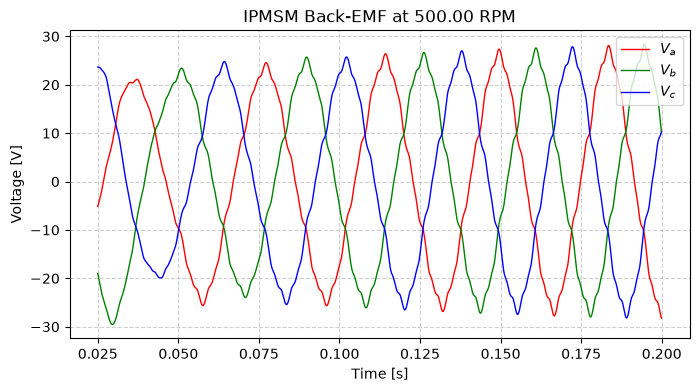

In [649]:
t_start = 0.025   # 시작 시간 [s]
t_end = 0.2     # 끝 시간 [s]

t_arr = np.asarray(time_history)
va_arr = np.asarray(v_a_history)

mask = (t_arr >= t_start) & (t_arr <= t_end)
labels = ["$V_a$", "$V_b$", "$V_c$"]
plt.figure(figsize=(8, 4))
for i in range(3):
    plt.plot(
        t_arr[mask],
        va_arr[mask, i],
        label=rf"{labels[i]}",
        color=colors_rgb[i],
        linewidth=1,
        alpha=1,
    )
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Time [s]')
plt.ylabel('Voltage [V]')
plt.legend(loc='upper right')
plt.title(rf'IPMSM Back-EMF at {target_speed_rpm:.2f} RPM')


seg = np.asarray(va_arr[mask, 1], dtype=float)
rms_val = float(np.sqrt(np.mean(seg ** 2)))
print(f"RMS: {rms_val:.4f}")

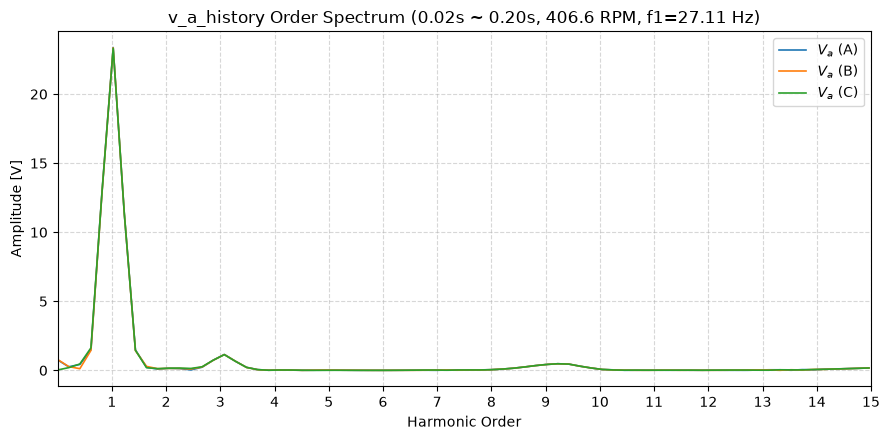

In [650]:
import numpy as np
import matplotlib.pyplot as plt

# 1) 시간 구간 설정
t_start = 0.02
t_end = 0.2

t_arr = np.asarray(time_history, dtype=float)
va_arr = np.asarray(v_a_history, dtype=float)
rpm_arr = np.asarray(speed_history, dtype=float)

n_min = min(len(t_arr), len(va_arr), len(rpm_arr))
t_arr = t_arr[:n_min]
va_arr = va_arr[:n_min]
rpm_arr = rpm_arr[:n_min]

mask = (t_arr >= t_start) & (t_arr <= t_end)
t_seg = t_arr[mask]
va_seg = va_arr[mask]
rpm_mean = float(np.mean(rpm_arr[mask]))

# 2) 샘플링 간격 및 전기 기본주파수 계산
dt_seg = float(np.mean(np.diff(t_seg)))
n = len(t_seg)
pole_pairs = iq5.pole_pairs
f_fund = (pole_pairs * rpm_mean) / 60.0  # 전기 기본주파수 [Hz]

win = np.hanning(n)
coherent_gain = np.sum(win) / n
freqs = np.fft.rfftfreq(n, d=dt_seg)
orders = freqs / f_fund

max_order = 15
order_mask = orders <= max_order
xticks = np.arange(1, max_order + 1, 1)

# 3) 채널별 FFT 진폭 계산 및 차수 플롯
plt.figure(figsize=(9, 4.5))
ch_labels = ["A", "B", "C"] if va_seg.shape[1] == 3 else [f"ch{k}" for k in range(va_seg.shape[1])]

for idx in range(va_seg.shape[1]):
    x_ac = (va_seg[:, idx] - np.mean(va_seg[:, idx])) * win
    fft_vals = np.fft.rfft(x_ac)
    amp = (2.0 / (n * coherent_gain)) * np.abs(fft_vals)
    if n % 2 == 0:
        amp[-1] *= 0.5

    plt.plot(
        orders[order_mask],
        amp[order_mask],
        linewidth=1.2,
        label=rf"$V_{{a}}$ ({ch_labels[idx]})",
    )

plt.xticks(xticks, [f"{k}" for k in xticks])
plt.xlim(0, max_order)
plt.xlabel("Harmonic Order")
plt.ylabel("Amplitude [V]")
plt.title(f"v_a_history Order Spectrum ({t_start:.2f}s ~ {t_end:.2f}s, {rpm_mean:.1f} RPM, f1={f_fund:.2f} Hz)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

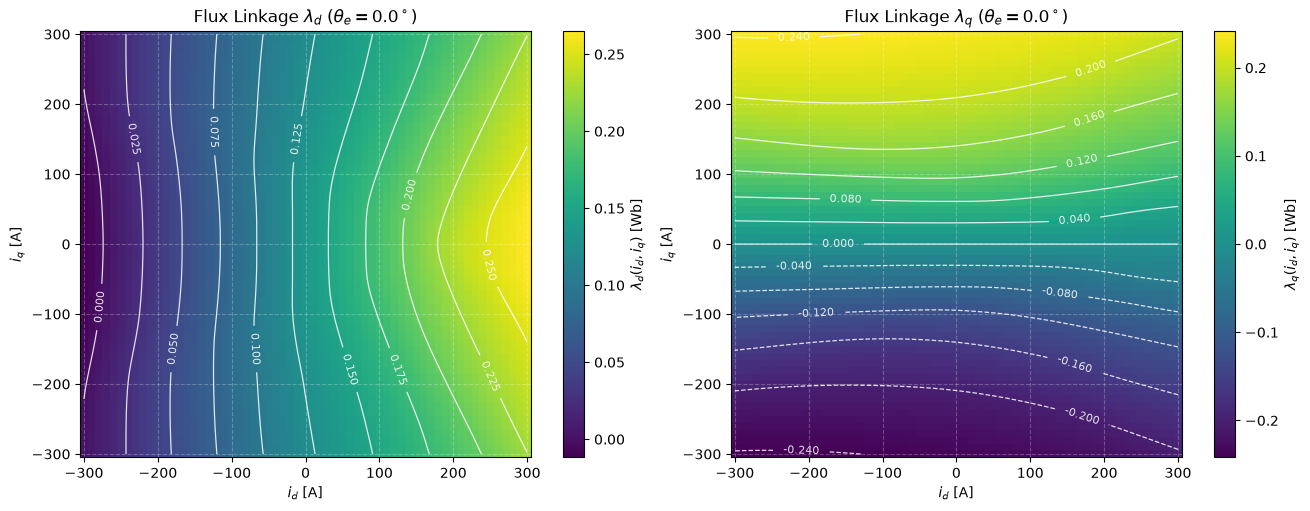

In [653]:
import numpy as np
import matplotlib.pyplot as plt

# 1) id, iq 탐색 범위 및 해상도 설정 [A]
id_vals = np.linspace(-300.0, 300.0, 61)
iq_vals = np.linspace(-300.0, 300.0, 61)
theta_deg = 0.0

ID, IQ = np.meshgrid(id_vals, iq_vals, indexing="ij")  # shape: (N_id, N_iq)

lam_d_map = np.zeros_like(ID, dtype=float)
lam_q_map = np.zeros_like(ID, dtype=float)

# 2) 그리드 점별 get_lambda 평가
for i_idx in range(ID.shape[0]):
    for j_idx in range(ID.shape[1]):
        _, _, lamda_dq0, _, _ = iq5.get_lambda(
            float(ID[i_idx, j_idx]),
            float(IQ[i_idx, j_idx]),
            theta_deg,
        )
        lam_dq0_arr = np.asarray(lamda_dq0, dtype=float).ravel()
        lam_d_map[i_idx, j_idx] = lam_dq0_arr[0]
        lam_q_map[i_idx, j_idx] = lam_dq0_arr[1]

# 3) 히트맵 + 등고선 플롯
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

plots = [
    (
        axes[0],
        lam_d_map,
        r"$\lambda_d(i_d, i_q)$ [Wb]",
        rf"Flux Linkage $\lambda_d$ ($\theta_e =  {theta_deg}^\circ$)",
        12,  # 등고선 개수 (또는 np.linspace(...) 배열 전달 가능)
    ),
    (
        axes[1],
        lam_q_map,
        r"$\lambda_q(i_d, i_q)$ [Wb]",
        rf"Flux Linkage $\lambda_q$ ($\theta_e =  {theta_deg}^\circ$)",
        12,
    ),
]

for ax, z_map, cbar_label, title, levels in plots:
    mesh = ax.pcolormesh(ID, IQ, z_map, shading="auto", cmap="viridis")
    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label(cbar_label)

    # 등고선 추가
    cs = ax.contour(
        ID,
        IQ,
        z_map,
        levels=levels,
        colors="white",
        linewidths=0.9,
        alpha=0.85,
    )
    ax.clabel(cs, inline=True, fontsize=8, fmt="%.3f")

    ax.set_xlabel(r"$i_d$ [A]")
    ax.set_ylabel(r"$i_q$ [A]")
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.25, color="white")

plt.show()

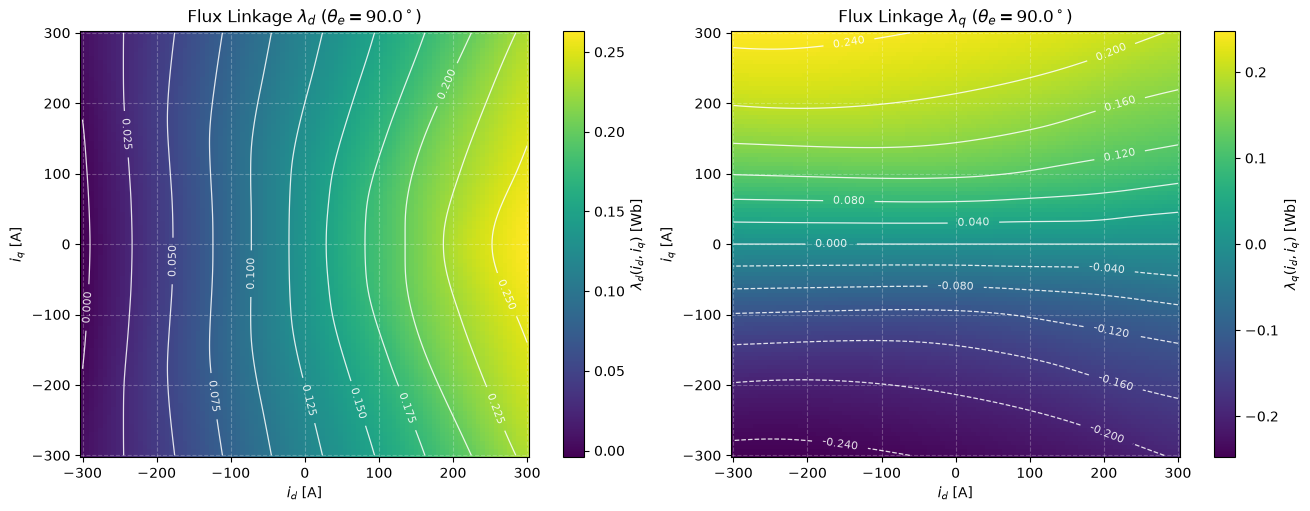

In [652]:
import numpy as np
import matplotlib.pyplot as plt

# 1) id, iq 탐색 범위 및 해상도 설정 [A]
id_vals = np.linspace(-300.0, 300.0, 101)
iq_vals = np.linspace(-300.0, 300.0, 101)
theta_deg = 90.0

ID, IQ = np.meshgrid(id_vals, iq_vals, indexing="ij")  # shape: (N_id, N_iq)

lam_d_map = np.zeros_like(ID, dtype=float)
lam_q_map = np.zeros_like(ID, dtype=float)

# 2) 그리드 점별 get_lambda 평가
for i_idx in range(ID.shape[0]):
    for j_idx in range(ID.shape[1]):
        _, _, lamda_dq0, _, _ = iq5.get_lambda(
            float(ID[i_idx, j_idx]),
            float(IQ[i_idx, j_idx]),
            theta_deg,
        )
        lam_dq0_arr = np.asarray(lamda_dq0, dtype=float).ravel()
        lam_d_map[i_idx, j_idx] = lam_dq0_arr[0]
        lam_q_map[i_idx, j_idx] = lam_dq0_arr[1]

# 3) 히트맵 + 등고선 플롯
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

plots = [
    (
        axes[0],
        lam_d_map,
        r"$\lambda_d(i_d, i_q)$ [Wb]",
        rf"Flux Linkage $\lambda_d$ ($\theta_e = {theta_deg}^\circ$)",
        12,  # 등고선 개수 (또는 np.linspace(...) 배열 전달 가능)
    ),
    (
        axes[1],
        lam_q_map,
        r"$\lambda_q(i_d, i_q)$ [Wb]",
        rf"Flux Linkage $\lambda_q$ ($\theta_e = {theta_deg}^\circ$)",
        12,
    ),
]

for ax, z_map, cbar_label, title, levels in plots:
    mesh = ax.pcolormesh(ID, IQ, z_map, shading="auto", cmap="viridis")
    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label(cbar_label)

    # 등고선 추가
    cs = ax.contour(
        ID,
        IQ,
        z_map,
        levels=levels,
        colors="white",
        linewidths=0.9,
        alpha=0.85,
    )
    ax.clabel(cs, inline=True, fontsize=8, fmt="%.3f")

    ax.set_xlabel(r"$i_d$ [A]")
    ax.set_ylabel(r"$i_q$ [A]")
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.25, color="white")

plt.show()

In [655]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# 1) id, iq 및 각도(theta) 탐색 범위 설정
id_vals = np.linspace(-300.0, 300.0, 101)
iq_vals = np.linspace(-300.0, 300.0, 101)
theta_list = np.arange(0.0, 360.0 + 10.0, 10.0)  # 0도 ~ 360도 (2도 단위, 총 181개)

ID, IQ = np.meshgrid(id_vals, iq_vals, indexing="ij")  # shape: (N_id, N_iq)

# 저장할 디렉토리 생성
save_dir = Path("flux_linkage_heatmaps")
save_dir.mkdir(parents=True, exist_ok=True)

# 2) 각도별 반복 계산 및 그래프 저장
for theta_deg in theta_list:
    lam_d_map = np.zeros_like(ID, dtype=float)
    lam_q_map = np.zeros_like(ID, dtype=float)

    # 그리드 점별 get_lambda 평가
    for i_idx in range(ID.shape[0]):
        for j_idx in range(ID.shape[1]):
            _, _, lamda_dq0, _, _ = iq5.get_lambda(
                float(ID[i_idx, j_idx]),
                float(IQ[i_idx, j_idx]),
                float(theta_deg),
            )
            lam_dq0_arr = np.asarray(lamda_dq0, dtype=float).ravel()
            lam_d_map[i_idx, j_idx] = lam_dq0_arr[0]
            lam_q_map[i_idx, j_idx] = lam_dq0_arr[1]

    # 3) 히트맵 + 등고선 플롯 생성
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

    plots = [
        (
            axes[0],
            lam_d_map,
            r"$\lambda_d(i_d, i_q)$ [Wb]",
            rf"Flux Linkage $\lambda_d$ ($\theta_e = {theta_deg:.0f}^\circ$)",
            12,
        ),
        (
            axes[1],
            lam_q_map,
            r"$\lambda_q(i_d, i_q)$ [Wb]",
            rf"Flux Linkage $\lambda_q$ ($\theta_e = {theta_deg:.0f}^\circ$)",
            12,
        ),
    ]

    for ax, z_map, cbar_label, title, levels in plots:
        mesh = ax.pcolormesh(ID, IQ, z_map, shading="auto", cmap="viridis")
        cbar = fig.colorbar(mesh, ax=ax)
        cbar.set_label(cbar_label)

        # 등고선 추가
        cs = ax.contour(
            ID,
            IQ,
            z_map,
            levels=levels,
            colors="white",
            linewidths=0.9,
            alpha=0.85,
        )
        ax.clabel(cs, inline=True, fontsize=8, fmt="%.3f")

        ax.set_xlabel(r"$i_d$ [A]")
        ax.set_ylabel(r"$i_q$ [A]")
        ax.set_title(title)
        ax.grid(True, linestyle="--", alpha=0.25, color="white")

    # 4) 파일 저장 및 메모리 해제 (예: flux_theta_000.png ~ flux_theta_360.png)
    filename = save_dir / f"flux_theta_{int(theta_deg):03d}.png"
    fig.savefig(filename, dpi=150)
    plt.close(fig)

    print(f"Saved: {filename}")

print("모든 각도의 히트맵 저장이 완료되었습니다.")

Saved: flux_linkage_heatmaps\flux_theta_000.png
Saved: flux_linkage_heatmaps\flux_theta_010.png
Saved: flux_linkage_heatmaps\flux_theta_020.png
Saved: flux_linkage_heatmaps\flux_theta_030.png
Saved: flux_linkage_heatmaps\flux_theta_040.png
Saved: flux_linkage_heatmaps\flux_theta_050.png
Saved: flux_linkage_heatmaps\flux_theta_060.png
Saved: flux_linkage_heatmaps\flux_theta_070.png
Saved: flux_linkage_heatmaps\flux_theta_080.png
Saved: flux_linkage_heatmaps\flux_theta_090.png
Saved: flux_linkage_heatmaps\flux_theta_100.png
Saved: flux_linkage_heatmaps\flux_theta_110.png
Saved: flux_linkage_heatmaps\flux_theta_120.png
Saved: flux_linkage_heatmaps\flux_theta_130.png
Saved: flux_linkage_heatmaps\flux_theta_140.png
Saved: flux_linkage_heatmaps\flux_theta_150.png
Saved: flux_linkage_heatmaps\flux_theta_160.png
Saved: flux_linkage_heatmaps\flux_theta_170.png
Saved: flux_linkage_heatmaps\flux_theta_180.png
Saved: flux_linkage_heatmaps\flux_theta_190.png
Saved: flux_linkage_heatmaps\flux_theta_